# **Weather Image Classification with Deep Learning: Training and Evaluation**

**Penulis:** `Rozhak`  
**Versi:** `1.0`  
**Proyek:** `WeatherImageClassifier`

**Tujuan:** Membangun model untuk mengklasifikasikan gambar ke dalam lima kelas cuaca (`shine`, `cloudy`, `foggy`, `sunrise`, dan `rainy`). Notebook ini mencakup persiapan dataset, pelatihan berbasis MobileNetV2, pemantauan metrik validasi, evaluasi pada data uji, dan penyimpanan model terpilih dalam format Keras (`.keras`).

**Cakupan:** Akuisisi dan pemeriksaan dataset, pemilihan kelas, pembagian data, prapemrosesan dan augmentasi gambar, pembangunan arsitektur, pelatihan bertahap, *fine-tuning*, evaluasi, serta ekspor model.

**Arsitektur Model:** `MobileNetV2 + Classification Head`

**Framework:** `TensorFlow / Keras`

## **1. Environment Setup**

Menyiapkan pustaka dan lingkungan kerja yang digunakan sepanjang alur proyek, mulai dari pengambilan dataset hingga penyimpanan model hasil pelatihan.

### **1.1 Install Dependencies**

Memasang pustaka tambahan untuk membagi dataset, mengunduh data melalui Kaggle CLI, serta menyediakan dukungan TensorFlow.js bila diperlukan.

In [1]:
%pip install split-folders tensorflowjs kaggle > /dev/null

### **1.2 Import Libraries and Configure Runtime**

Memuat modul untuk mengelola berkas, memproses gambar, membangun dan melatih model TensorFlow/Keras, serta memvisualisasikan hasil.

In [2]:
from google.colab import files

import splitfolders
import os
import shutil

import tensorflow as tf
import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns

from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import (
    Input,
    Conv2D,
    MaxPooling2D,
    GlobalAveragePooling2D,
    Dense,
    Dropout,
    BatchNormalization,
)

from tensorflow.keras.applications import MobileNetV2
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.callbacks import (
    EarlyStopping,
    ModelCheckpoint,
    ReduceLROnPlateau,
)
from tensorflow.keras.applications.mobilenet_v2 import preprocess_input

print(f"[ENVIRONMENT] tensorflow={tf.__version__} | status=READY")

[ENVIRONMENT] tensorflow=2.21.0 | status=READY


## **2. Dataset Acquisition**

Mengatur sumber dataset Kaggle, mengunduh dan mengekstrak data ke direktori kerja, lalu memeriksa hasil ekstraksi sebelum persiapan dataset dimulai.

### **2.1 Dataset Source**

Menetapkan ID dataset Kaggle dan direktori penyimpanannya. Variabel `source_dir` menunjuk ke folder hasil ekstraksi yang digunakan pada tahap berikutnya.

In [3]:
DATASET_SOURCE = "vijaygiitk/multiclass-weather-dataset"
DATASET_ROOT = "/content/dataset"
source_dir = os.path.join(DATASET_ROOT, "dataset")

print(f"[DATASET] source=KAGGLE | dataset='{DATASET_SOURCE}'")

[DATASET] source=KAGGLE | dataset='vijaygiitk/multiclass-weather-dataset'


### **2.2 Download and Extract Dataset**

Mengunggah `kaggle.json`, menyalin kredensial ke direktori konfigurasi Kaggle dengan izin akses terbatas, lalu mengunduh dan mengekstrak dataset ke `DATASET_ROOT`.

In [ ]:
files.upload()

if not os.path.isfile("kaggle.json"):
    raise FileNotFoundError("File kaggle.json tidak ditemukan.")

kaggle_dir = os.path.expanduser("~/.kaggle")
os.makedirs(kaggle_dir, exist_ok=True)

shutil.copy2("kaggle.json", os.path.join(kaggle_dir, "kaggle.json"))
os.chmod(os.path.join(kaggle_dir, "kaggle.json"), 0o600)

os.makedirs(DATASET_ROOT, exist_ok=True)

print(f"[DATASET] source=KAGGLE | dataset='{DATASET_SOURCE}' | status=DOWNLOADING")
!kaggle datasets download -d {DATASET_SOURCE} -p {DATASET_ROOT} --unzip
print(f"[DATASET] source=KAGGLE | dataset='{DATASET_SOURCE}' | status=DOWNLOADED")

Saving kaggle.json to kaggle (2).json
[DATASET] source=KAGGLE | dataset='vijaygiitk/multiclass-weather-dataset' | status=DOWNLOADING
Dataset URL: https://www.kaggle.com/datasets/vijaygiitk/multiclass-weather-dataset
License(s): CC0-1.0
100% 134M/134M [00:00<00:00, 364MB/s]

[DATASET] source=KAGGLE | dataset='vijaygiitk/multiclass-weather-dataset' | status=DOWNLOADED


### **2.3 Verify Source Directory**

Memastikan direktori hasil ekstraksi tersedia. Jika direktori tidak ditemukan, proses dihentikan dengan `FileNotFoundError` agar langkah berikutnya tidak berjalan menggunakan lokasi dataset yang salah.

In [5]:
if not os.path.isdir(source_dir):
    raise FileNotFoundError(
        f"Direktori dataset tidak ditemukan: {source_dir}"
    )

print(f"[VALIDATION] dataset_path='{source_dir}' | status=READY")

[VALIDATION] dataset_path='/content/dataset/dataset' | status=READY


## **3. Dataset Preparation and Exploration**

Memilih lima kelas cuaca yang akan diprediksi, memeriksa jumlah file pada tiap kelas, lalu membagi dataset menjadi data train, validation, dan test.

### **3.1 Select Target Classes**

Membatasi dataset pada lima kelas yang dibutuhkan. Kode memeriksa apakah semua folder kelas tersedia, lalu menyalin isinya ke direktori bersih yang menjadi sumber untuk pembagian data.

In [6]:
valid_classes = ["shine", "cloudy", "foggy", "sunrise", "rainy"]
clean_dir = os.path.join(DATASET_ROOT, "clean_dataset")

missing_classes = [
    name for name in valid_classes
    if not os.path.isdir(os.path.join(source_dir, name))
]

if missing_classes:
        raise FileNotFoundError(
        f"Kelas dataset tidak ditemukan: {missing_classes}"
    )

if os.path.exists(clean_dir):
    shutil.rmtree(clean_dir)

os.makedirs(clean_dir)

for class_name in valid_classes:
    shutil.copytree(
        os.path.join(source_dir, class_name),
        os.path.join(clean_dir, class_name),
    )

base_dir = clean_dir

print(f"[DATASET] classes={valid_classes} | status=READY")

[DATASET] classes=['shine', 'cloudy', 'foggy', 'sunrise', 'rainy'] | status=READY


### **3.2 Inspect Class Distribution**

Menghitung jumlah entri pada setiap folder kelas dan menampilkannya dalam grafik batang. Angka ini mencerminkan isi direktori; kode tidak memeriksa apakah setiap entri merupakan gambar yang valid dan dapat dibaca.

In [7]:
class_names = sorted(os.listdir(base_dir))
class_counts = {
    name: len(os.listdir(os.path.join(base_dir, name)))
    for name in class_names
}

for class_name, count in class_counts.items():
    print(f"[DATASET] class='{class_name}' | images={count}")

[DATASET] class='cloudy' | images=300
[DATASET] class='foggy' | images=300
[DATASET] class='rainy' | images=300
[DATASET] class='shine' | images=250
[DATASET] class='sunrise' | images=350


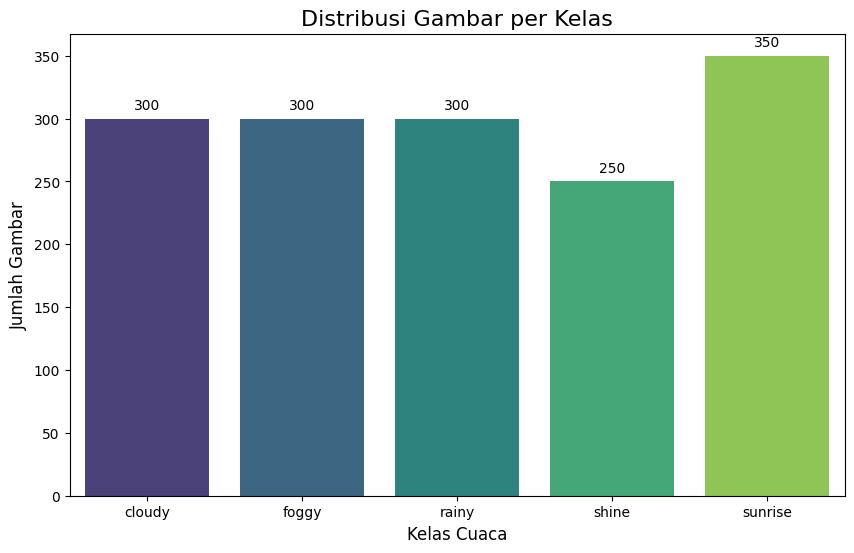

In [8]:
plt.figure(figsize=(10, 6))
sns.barplot(
    x=list(class_counts.keys()),
    y=list(class_counts.values()),
    palette="viridis",
    hue=list(class_counts.keys()),
    dodge=False,
    legend=False,
)

plt.title("Distribusi Gambar per Kelas", fontsize=16)
plt.xlabel("Kelas Cuaca", fontsize=12)
plt.ylabel("Jumlah Gambar", fontsize=12)

for i, count in enumerate(class_counts.values()):
    plt.text(i, count + 5, str(count), ha="center", va="bottom", fontsize=10)

plt.show()

### **3.3 Split Dataset into Train, Validation, and Test Sets**

Membagi dataset menjadi 60% train, 20% validation, dan 20% test menggunakan `seed=42`. Seed membantu menjaga konsistensi pembagian selama isi dan susunan data sumber tetap sama.

In [9]:
output_dir = os.path.join(DATASET_ROOT, "weather_split")

if os.path.exists(output_dir):
    shutil.rmtree(output_dir)

splitfolders.ratio(
    base_dir,
    output=output_dir,
    seed=42,
    ratio=(0.6, 0.2, 0.2),
    group_prefix=None,
    move=False,
)

train_dir = os.path.join(output_dir, "train")
validation_dir = os.path.join(output_dir, "val")
test_dir = os.path.join(output_dir, "test")

print(f"[DATASET] split=60/20/20 | seed=42 | status=READY")

Copying files: 1500 files [00:00, 4235.59 files/s]

[DATASET] split=60/20/20 | seed=42 | status=READY


### **3.4 Verify Dataset Split**

Memastikan folder `train`, `val`, dan `test` tersedia, lalu menghitung jumlah entri per kelas dan total untuk setiap split. Hasilnya membantu memeriksa apakah struktur pembagian data terbentuk sesuai harapan.

In [10]:
split_dirs = {
    "train": train_dir,
    "val": validation_dir,
    "test": test_dir,
}

for split, split_path in split_dirs.items():
    if not os.path.isdir(split_path):
        raise FileNotFoundError(
            f"Direktori split '{split}' tidak ditemukan: {split_path}"
        )

    total_images = 0

    for class_name in sorted(os.listdir(split_path)):
        class_path = os.path.join(split_path, class_name)

        if not os.path.isdir(class_path):
            continue

        count = len(os.listdir(class_path))
        total_images += count

        print(
            f"[DATASET] split='{split}' | "
            f"class='{class_name}' | images={count}"
        )

    print(f"[DATASET] split='{split}' | total_images={total_images}")

print(f"[VALIDATION] dataset_path='{output_dir}' | splits={list(split_dirs)} | status=READY")

[DATASET] split='train' | class='cloudy' | images=180
[DATASET] split='train' | class='foggy' | images=180
[DATASET] split='train' | class='rainy' | images=180
[DATASET] split='train' | class='shine' | images=150
[DATASET] split='train' | class='sunrise' | images=210
[DATASET] split='train' | total_images=900
[DATASET] split='val' | class='cloudy' | images=60
[DATASET] split='val' | class='foggy' | images=60
[DATASET] split='val' | class='rainy' | images=60
[DATASET] split='val' | class='shine' | images=50
[DATASET] split='val' | class='sunrise' | images=70
[DATASET] split='val' | total_images=300
[DATASET] split='test' | class='cloudy' | images=60
[DATASET] split='test' | class='foggy' | images=60
[DATASET] split='test' | class='rainy' | images=60
[DATASET] split='test' | class='shine' | images=50
[DATASET] split='test' | class='sunrise' | images=70
[DATASET] split='test' | total_images=300
[VALIDATION] dataset_path='/content/dataset/weather_split' | splits=['train', 'val', 'test'] | 

## **4. Image Preprocessing**

Menyiapkan generator gambar untuk ketiga split dengan ukuran input yang seragam. Augmentasi acak hanya diterapkan pada data train; validation dan test memakai preprocessing MobileNetV2 tanpa augmentasi.

### **4.1 Configure Image Size and Batch Size**

Menetapkan ukuran input 224 × 224 piksel dengan tiga kanal warna, serta `batch_size` sebesar 32 untuk setiap generator.

In [11]:
IMAGE_SIZE = (224, 224)
BATCH_SIZE = 32

### **4.2 Configure Training Augmentation**

Menerapkan `preprocess_input` dari MobileNetV2 pada gambar sebelum masuk ke model. Untuk data train, generator juga menerapkan augmentasi berupa rotasi, pergeseran, shear, zoom, dan flip horizontal.

Data validation dan test menggunakan preprocessing MobileNetV2 tanpa augmentasi acak agar evaluasi dilakukan tanpa perubahan gambar tambahan.

In [12]:
train_datagen = ImageDataGenerator(
    preprocessing_function=preprocess_input,
    rotation_range=30,
    width_shift_range=0.2,
    height_shift_range=0.2,
    shear_range=0.2,
    zoom_range=0.2,
    horizontal_flip=True,
    fill_mode="nearest",
)

test_datagen = ImageDataGenerator(
    preprocessing_function=preprocess_input
)

### **4.3 Create Training, Validation, and Test Generators**

Membuat generator dari folder masing-masing dengan ukuran gambar dan batch size yang sama. `class_mode="categorical"` menyiapkan label untuk klasifikasi multikelas; data train diacak, sedangkan urutan validation dan test dipertahankan.

In [13]:
train_generator = train_datagen.flow_from_directory(
    train_dir,
    target_size=IMAGE_SIZE,
    batch_size=BATCH_SIZE,
    class_mode="categorical",
    shuffle=True,
)

validation_generator = test_datagen.flow_from_directory(
    validation_dir,
    target_size=IMAGE_SIZE,
    batch_size=BATCH_SIZE,
    class_mode="categorical",
    shuffle=False,
)

test_generator = test_datagen.flow_from_directory(
    test_dir,
    target_size=IMAGE_SIZE,
    batch_size=BATCH_SIZE,
    class_mode="categorical",
    shuffle=False,
)

Found 900 images belonging to 5 classes.
Found 300 images belonging to 5 classes.
Found 300 images belonging to 5 classes.


## **5. Model Architecture**

Menggunakan MobileNetV2 pralatih sebagai backbone untuk mengekstraksi fitur gambar, lalu menambahkan classification head yang memetakan fitur tersebut ke lima kelas cuaca.

### **5.1 Load MobileNetV2 Backbone**

Memuat MobileNetV2 dengan bobot pralatih ImageNet dan `include_top=False`, sehingga lapisan klasifikasi aslinya tidak digunakan. Backbone dibekukan pada awal training agar tahap pertama hanya memperbarui classification head.

In [14]:
base_model = MobileNetV2(
    weights="imagenet",
    include_top=False,
    input_shape=(224, 224, 3),
)

base_model.trainable = False

### **5.2 Define Classification Head**

Menambahkan lapisan `Conv2D` dan `MaxPooling2D`, merangkum fitur dengan `GlobalAveragePooling2D`, lalu menggunakan `Dense`, `BatchNormalization`, dan `Dropout` sebagai classification head. Lapisan `softmax` menghasilkan probabilitas prediksi untuk masing-masing dari lima kelas.

In [15]:
model = Sequential([
    Input(shape=(224, 224, 3)),
    base_model,
    Conv2D(32, (3, 3), activation="relu", padding="same"),
    MaxPooling2D((2, 2)),
    GlobalAveragePooling2D(),
    Dense(1024, activation="relu"),
    BatchNormalization(),
    Dropout(0.5),
    Dense(len(class_names), activation="softmax"),
])

### **5.3 Inspect Model Architecture**

Menampilkan ringkasan arsitektur, bentuk input dan output, serta jumlah parameter yang trainable dan non-trainable. Informasi ini membantu memeriksa konfigurasi model sebelum training.

In [16]:
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ mobilenetv2_1.00_224            │ (None, 7, 7, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 7, 7, 32)       │       368,672 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 3, 3, 32)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 32)             │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 1024)           │        33,792 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 1024)           │         4,096 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 1024)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 5)              │         5,125 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,669,669 (10.18 MB)

 Trainable params: 409,637 (1.56 MB)

 Non-trainable params: 2,260,032 (8.62 MB)

## **6. Model Training**

Melatih model dalam dua tahap: pertama melatih classification head saat backbone dibekukan, lalu melakukan fine-tuning pada bagian backbone yang dibuka untuk training dengan learning rate lebih rendah.

### **6.1 Stage 1 — Train the Classification Head**

Melatih classification head menggunakan Adam dengan `learning_rate=0.001`, `categorical_crossentropy`, dan metrik `accuracy`. Tahap ini berjalan hingga 20 epoch, tetapi dapat berhenti lebih awal jika `val_loss` tidak membaik.

Learning rate diturunkan ketika `val_loss` tidak membaik, dan early stopping menghentikan training jika perbaikan tidak berlanjut. Checkpoint dengan `val_loss` terendah disimpan sebagai `best_model_stage1.keras`.

In [17]:
model.compile(
    optimizer=Adam(learning_rate=1e-3),
    loss="categorical_crossentropy",
    metrics=["accuracy"],
)

cb_stage1 = [
    ReduceLROnPlateau(
        monitor="val_loss",
        factor=0.2,
        patience=3,
        min_lr=1e-6,
        verbose=1,
    ),
    EarlyStopping(
        monitor="val_loss",
        patience=6,
        mode="min",
        restore_best_weights=True,
        verbose=1,
    ),
    ModelCheckpoint(
        "best_model_stage1.keras",
        monitor="val_loss",
        save_best_only=True,
        mode="min",
        verbose=1,
    ),
]

history_stage1 = model.fit(
    train_generator,
    epochs=20,
    validation_data=validation_generator,
    callbacks=cb_stage1,
    verbose=1,
)

Epoch 1/20
29/29 ━━━━━━━━━━━━━━━━━━━━ 0s 664ms/step - accuracy: 0.5822 - loss: 1.1565
Epoch 1: val_loss improved from None to 1.52742, saving model to best_model_stage1.keras

Epoch 1: finished saving model to best_model_stage1.keras
29/29 ━━━━━━━━━━━━━━━━━━━━ 43s 1s/step - accuracy: 0.6878 - loss: 0.8888 - val_accuracy: 0.5433 - val_loss: 1.5274 - learning_rate: 0.0010
Epoch 2/20
29/29 ━━━━━━━━━━━━━━━━━━━━ 0s 454ms/step - accuracy: 0.8677 - loss: 0.3522
Epoch 2: val_loss improved from 1.52742 to 0.34404, saving model to best_model_stage1.keras

Epoch 2: finished saving model to best_model_stage1.keras
29/29 ━━━━━━━━━━━━━━━━━━━━ 15s 533ms/step - accuracy: 0.8667 - loss: 0.3640 - val_accuracy: 0.8967 - val_loss: 0.3440 - learning_rate: 0.0010
Epoch 3/20
29/29 ━━━━━━━━━━━━━━━━━━━━ 0s 455ms/step - accuracy: 0.9099 - loss: 0.2746
Epoch 3: val_loss did not improve from 0.34404
29/29 ━━━━━━━━━━━━━━━━━━━━ 15s 514ms/step - accuracy: 0.9011 - loss: 0.2734 - val_accuracy: 0.8467 - val_loss: 0.69

### **6.2 Stage 2 — Fine-Tune MobileNetV2**

Membuka backbone MobileNetV2 untuk fine-tuning, tetapi 100 lapisan pertamanya tetap dibekukan. Training menggunakan Adam dengan `learning_rate=0.00001`; `val_accuracy` dipakai untuk memantau perkembangan dan memilih checkpoint terbaik.

Parameter `epochs=30` menetapkan batas nomor epoch keseluruhan, sedangkan `initial_epoch` dimulai dari jumlah epoch yang selesai pada tahap pertama. Jika tahap pertama berjalan 20 epoch, fine-tuning dapat berjalan paling banyak 10 epoch tambahan. Checkpoint dengan `val_accuracy` tertinggi disimpan sebagai `best_model_fine_tuned.keras`.

In [18]:
base_model.trainable = True

fine_tune_at = 100

for layer in base_model.layers[:fine_tune_at]:
    layer.trainable = False

model.compile(
    optimizer=Adam(learning_rate=1e-5),
    loss="categorical_crossentropy",
    metrics=["accuracy"],
)

cb_stage2 = [
    EarlyStopping(
        monitor="val_accuracy",
        patience=8,
        mode="max",
        restore_best_weights=True,
        verbose=1,
    ),
    ModelCheckpoint(
        "best_model_fine_tuned.keras",
        monitor="val_accuracy",
        save_best_only=True,
        mode="max",
        verbose=1,
    ),
    ReduceLROnPlateau(
        monitor="val_accuracy",
        factor=0.2,
        patience=4,
        min_lr=1e-7,
        verbose=1,
    ),
]

history_fine_tune = model.fit(
    train_generator,
    epochs=30,
    initial_epoch=len(history_stage1.history["loss"]),
    validation_data=validation_generator,
    callbacks=cb_stage2,
    verbose=1,
)

Epoch 20/30
29/29 ━━━━━━━━━━━━━━━━━━━━ 0s 851ms/step - accuracy: 0.8355 - loss: 0.5271
Epoch 20: val_accuracy improved from None to 0.94333, saving model to best_model_fine_tuned.keras

Epoch 20: finished saving model to best_model_fine_tuned.keras
29/29 ━━━━━━━━━━━━━━━━━━━━ 56s 1s/step - accuracy: 0.8467 - loss: 0.4593 - val_accuracy: 0.9433 - val_loss: 0.1924 - learning_rate: 1.0000e-05
Epoch 21/30
29/29 ━━━━━━━━━━━━━━━━━━━━ 0s 466ms/step - accuracy: 0.8681 - loss: 0.4090
Epoch 21: val_accuracy improved from 0.94333 to 0.95000, saving model to best_model_fine_tuned.keras

Epoch 21: finished saving model to best_model_fine_tuned.keras
29/29 ━━━━━━━━━━━━━━━━━━━━ 16s 550ms/step - accuracy: 0.8733 - loss: 0.3683 - val_accuracy: 0.9500 - val_loss: 0.2061 - learning_rate: 1.0000e-05
Epoch 22/30
29/29 ━━━━━━━━━━━━━━━━━━━━ 0s 459ms/step - accuracy: 0.8983 - loss: 0.3723
Epoch 22: val_accuracy did not improve from 0.95000
29/29 ━━━━━━━━━━━━━━━━━━━━ 15s 512ms/step - accuracy: 0.8967 - loss: 0.

## **7. Training Performance**

Meninjau perubahan performa model sepanjang tahap training dan fine-tuning menggunakan metrik accuracy dan loss pada data train serta validation.

### **7.1 Combine Training Histories**

Menggabungkan riwayat `accuracy`, `val_accuracy`, `loss`, dan `val_loss` dari kedua tahap ke dalam urutan epoch yang sama. Data gabungan ini digunakan untuk membuat grafik performa.

In [19]:
acc = history_stage1.history["accuracy"] + history_fine_tune.history["accuracy"]
val_acc = history_stage1.history["val_accuracy"] + history_fine_tune.history["val_accuracy"]
loss = history_stage1.history["loss"] + history_fine_tune.history["loss"]
val_loss = history_stage1.history["val_loss"] + history_fine_tune.history["val_loss"]

### **7.2 Plot Accuracy and Loss**

Menampilkan grafik `accuracy` dan `loss` pada data train serta validation sepanjang epoch yang tercatat. Garis 85% menunjukkan target acuan; garis tersebut tidak berarti model telah mencapai target.

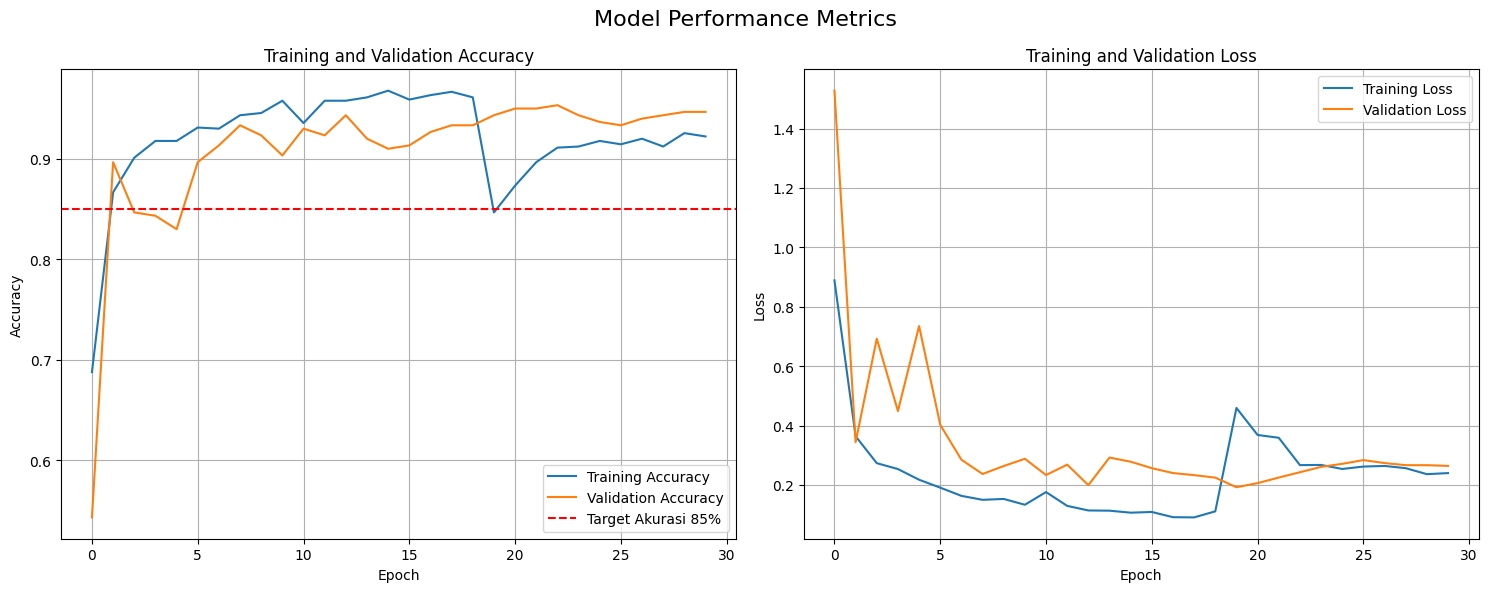

In [20]:
plt.figure(figsize=(15, 6))

plt.subplot(1, 2, 1)
plt.plot(acc, label="Training Accuracy")
plt.plot(val_acc, label="Validation Accuracy")
plt.axhline(y=0.85, color="r", linestyle="--", label="Target Akurasi 85%")
plt.title("Training and Validation Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend(loc="lower right")
plt.grid(True)

plt.subplot(1, 2, 2)
plt.plot(loss, label="Training Loss")
plt.plot(val_loss, label="Validation Loss")
plt.title("Training and Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend(loc="upper right")
plt.grid(True)

plt.suptitle("Model Performance Metrics", fontsize=16)
plt.tight_layout()
plt.show()

## **8. Model Evaluation**

Mengukur `loss` dan `accuracy` pada data train dan test menggunakan checkpoint terbaik dari tahap fine-tuning. Data test tidak digunakan untuk memperbarui bobot selama training.

### **8.1 Evaluate the Selected Checkpoint on the Training Set**

Memuat `best_model_fine_tuned.keras`, lalu menghitung `loss` dan `accuracy` pada generator train. Karena generator train menerapkan augmentasi acak, gambar yang dievaluasi dapat berbeda antar pemanggilan; metrik ini bukan evaluasi pada gambar train dalam bentuk tetap.

In [21]:
model = tf.keras.models.load_model(
    "best_model_fine_tuned.keras"
)

train_loss, train_accuracy = model.evaluate(
    train_generator,
    verbose=1,
)

print(f"[EVALUATION] dataset=train | loss={train_loss:.4f} | accuracy={train_accuracy:.2%}")

29/29 ━━━━━━━━━━━━━━━━━━━━ 20s 535ms/step - accuracy: 0.9511 - loss: 0.1488
[EVALUATION] dataset=train | loss=0.1488 | accuracy=95.11%


### **8.2 Evaluate the Selected Checkpoint on the Test Set**

Menghitung `loss` dan `accuracy` pada test set yang tidak digunakan untuk memperbarui bobot atau memilih checkpoint. Hasil ini memberikan ukuran performa model pada data yang tidak dilihat selama proses training.

In [22]:
test_loss, test_accuracy = model.evaluate(
    test_generator,
    verbose=1,
)

print(f"[EVALUATION] dataset=test | loss={test_loss:.4f} | accuracy={test_accuracy:.2%}")

10/10 ━━━━━━━━━━━━━━━━━━━━ 4s 441ms/step - accuracy: 0.9200 - loss: 0.3092
[EVALUATION] dataset=test | loss=0.3092 | accuracy=92.00%


## **9. Model Export**

Menyimpan checkpoint terbaik dari tahap fine-tuning sebagai berkas model Keras, lalu memuat kembali berkas tersebut untuk memeriksa bahwa artefak hasil ekspor dapat digunakan.

### **9.1 Save the Selected Model**

Memuat checkpoint `best_model_fine_tuned.keras` dan menyimpannya ke `models/weather_classifier.keras`. Checkpoint sumber dipilih berdasarkan `val_accuracy` tertinggi selama fine-tuning.

In [23]:
MODEL_PATH = "models/weather_classifier.keras"

os.makedirs(os.path.dirname(MODEL_PATH), exist_ok=True)

model = tf.keras.models.load_model("best_model_fine_tuned.keras")
model.save(MODEL_PATH)

print(f"[EXPORT] format=Keras | path='{MODEL_PATH}' | status=COMPLETED")

[EXPORT] format=Keras | path='models/weather_classifier.keras' | status=COMPLETED


### **9.2 Verify the Exported Model Artifact**

Memastikan berkas hasil ekspor tersedia, memuatnya kembali, lalu menampilkan bentuk input dan output model. Pemeriksaan ini memastikan artefak dapat ditemukan dan dimuat.

In [24]:
if not os.path.isfile(MODEL_PATH):
    raise FileNotFoundError(f"Model artifact tidak ditemukan: {MODEL_PATH}")

loaded_model = tf.keras.models.load_model(MODEL_PATH)

print(
    f"[VALIDATION] model_path='{MODEL_PATH}' | "
    f"input_shape={loaded_model.input_shape} | "
    f"output_shape={loaded_model.output_shape} | "
    f"status=READY"
)

[VALIDATION] model_path='models/weather_classifier.keras' | input_shape=(None, 224, 224, 3) | output_shape=(None, 5) | status=READY
